(r-comparisons-continuous)=

# Continuous treatment in ModernDiD and R

This comparison checks whether the county employment analysis of the
fracking panel gives the same results in ModernDiD and R's `contdid`
package. We fit {func}`~moderndid.cont_did` in both languages and compare
the overall effects and the fitted curves at every score. Both calls use a
cubic spline without interior knots and compare treated counties with
counties that have not yet received treatment.

The overall ATT and ACRT estimates agree to floating-point precision. The dose
curves and every standard error differ because `contdid` 0.1.1 and the
`ptetools` 1.0.1 functions it calls depart in two ways from the method of
Callaway, Goodman-Bacon, and Sant'Anna (2025) that both packages implement.
They evaluate each cohort's fitted spline on a basis built from the grid's
endpoints rather than the basis it was fit on. Their influence functions also
scale the ACRT's cell terms by every county in the cell and drop or shrink the
term for estimated cohort weights. The sections below trace each gap to the R
code that produces it and show how large it is on this data.

R runs inside the Python session through `rpy2` and receives the same
observations. The section on {ref}`running the comparisons <r-comparisons-running>`
explains how to install the R packages and rerun the comparison locally.

:::{admonition} What this comparison checks
:class: note

The assertions hold the two overall estimates to the common tolerance and
check that ModernDiD's curves do not move with the grid. Since R computes
the dose curves and the influence functions differently, those values appear
side by side without an assertion. Each language also draws its own random
multipliers for the bootstrap standard errors.
:::

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from IPython.display import display
from rpy2 import robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.packages import importr

import moderndid as did

with ro.default_converter.context():
    r_contdid = importr("contdid")

pd.set_option("display.precision", 8)

## The same counties, years, and scores

The bundled fracking panel from {func}`~moderndid.load_fracking` is the one
that the {ref}`continuous treatment example <example_cont_did>` analyzes. It
contains 402 counties observed annually from 1990 through 2014. The outcome
`y` is already log total employment, `i` identifies counties, and `t` gives
the calendar year. The geological prospectivity score `d` stays fixed within
each county. `G` records the adoption year of the county's formation and
stays at zero throughout the panel for a coded-zero county.

:::{admonition} How the scores were coded
:class: note

Coded zeros include prospectivity scores that were originally missing. The
scores were also constructed separately within each shale play. The
{ref}`continuous treatment example <example_cont_did>` explains why these
coding and scale choices matter for interpreting the estimates.
:::

The code keeps the five estimation columns of the loader's complete panel of
10,050 county-years. Before fitting, we encode the years 1990 through 2014
as periods 1 through 25 and give each positive adoption year the same
encoding. Untreated counties keep zero as their adoption code in both
languages. The original years stay available in the `calendar_year` and
`adoption_year` columns. Both implementations receive the same data with
every county-year still in the sample. The 20-score grid from 3.0 to 4.6
stays inside the range from 2.99 to 4.67 that every adoption cohort observes
and drops no county from estimation.

:::{admonition} Encode calendar years consistently
:class: important

The installed R implementation restores calendar-year labels for its
estimated cohorts but keeps integer cohort codes in the data that computes
the overall weights. Passing calendar years directly therefore stops R with
a missing-weight error. Encoding both observation and adoption years as
consecutive periods in both languages avoids that mismatch without changing
the observations or the relative treatment timing.
:::

In [2]:
data = did.load_fracking().select("i", "t", "G", "d", "y")
first_year = data["t"].min()
data = data.with_columns(
    pl.col("t").alias("calendar_year"),
    pl.col("G").alias("adoption_year"),
    (pl.col("t") - first_year + 1).alias("t"),
    pl.when(pl.col("G") > 0).then(pl.col("G") - first_year + 1).otherwise(0).alias("G"),
)
dvals = np.linspace(3.0, 4.6, 20)

In [3]:
with (ro.default_converter + pandas2ri.converter).context():
    r_data = ro.conversion.py2rpy(data.to_pandas())
with ro.default_converter.context():
    ro.globalenv["panel"] = r_data
    ro.globalenv["dvals"] = ro.FloatVector(dvals)

## Fit the same specification

The two calls print the Python result and then the R summary. Both evaluate
the curves at the same 20 scores and use 199 multiplier bootstrap draws for
pointwise uncertainty. Since post-adoption comparisons use the year before
adoption under either base period, the dose curves keep the post-adoption
target of the continuous treatment example.

Of the two packages, only ModernDiD reads the comparison-group and
base-period arguments that both calls pass. In `contdid` 0.1.1, `cont_did()`
never passes `control_group` or `base_period` on to `ptetools::pte()`. Its
subset function `cont_two_by_two_subset()` then falls back to its own
defaults, not-yet-treated comparisons and a varying base period.

:::{admonition} `contdid` ignores both settings
:class: warning

A `contdid` call that asks for never-treated comparisons or a universal base
period silently returns the same numbers as one that does not. The agreement
on this page therefore holds only for not-yet-treated comparisons. Since only
ModernDiD's estimates move when you ask for never-treated comparisons, report
ModernDiD's numbers for that design.
:::

In [4]:
python_fit = did.cont_did(
    data,
    yname="y", tname="t", idname="i", gname="G", dname="d",
    target_parameter="level", aggregation="dose", treatment_type="continuous",
    dose_est_method="parametric", control_group="notyettreated", base_period="varying",
    degree=3, num_knots=0, dvals=dvals,
    biters=199, cband=False, random_state=42,
)
print(python_fit)

 Continuous Treatment Dose-Response Results

 Overall ATT:

┌────────┬────────────┬────────────────────────┐
│    ATT │ Std. Error │ [95% Conf. Interval]   │
├────────┼────────────┼────────────────────────┤
│ 0.0424 │     0.0097 │ [  0.0234,   0.0615] * │
└────────┴────────────┴────────────────────────┘

 Overall ACRT:

┌────────┬────────────┬────────────────────────┐
│   ACRT │ Std. Error │ [95% Conf. Interval]   │
├────────┼────────────┼────────────────────────┤
│ 0.0442 │     0.0105 │ [  0.0236,   0.0648] * │
└────────┴────────────┴────────────────────────┘

------------------------------------------------------------------------------
 Signif. codes: '*' confidence band does not cover 0

------------------------------------------------------------------------------
 Data Info
------------------------------------------------------------------------------
 Control Group: Not Yet Treated
 Anticipation Periods: 0

------------------------------------------------------------------------

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
/Users/jordandeklerk/moderndid/moderndid/didcont/estimation/process_attgt.py:91: UserWarning: Not returning pre-test Wald statistic due to singular covariance matrix
  warnings.warn("Not returning pre-test Wald statistic due to singular covariance matrix", UserWarning)


In [5]:
with ro.default_converter.context():
    ro.r("set.seed(42)")
    r_fit = ro.r("""
        contdid::cont_did(
            data = panel,
            yname = "y", tname = "t", idname = "i", gname = "G", dname = "d",
            target_parameter = "level", aggregation = "dose", treatment_type = "continuous",
            dose_est_method = "parametric", control_group = "notyettreated", base_period = "varying",
            degree = 3, num_knots = 0, dvals = dvals,
            bstrap = TRUE, biters = 199, cband = FALSE
        )
    """)
    _ = ro.r["print"](ro.r["summary"](r_fit))


Overall ATT:  
    ATT    Std. Error     [ 95%  Conf. Int.]  
 0.0424        0.0085     0.0257      0.0591 *


Overall ACRT:  
   ACRT    Std. Error     [ 95%  Conf. Int.]  
 0.0442        0.0035     0.0372      0.0511 *
---
Signif. codes: `*' confidence band does not cover 0



R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: In mboot2(thisinffunc, biters = biters, alp = alp) :  
R callback write-console: 
   
R callback write-console:  critical value for uniform confidence band is somehow smaller than
            critical value for pointwise confidence interval...using pointwise
            confidence interal
  


## Compare the reported values

The overall ATT averages the level effects over the treated score
distribution. The overall ACRT averages the fitted dose derivatives over the
same distribution. Reading it causally requires the stronger assumptions
described in {ref}`background-didcont`.

The next table extracts these quantities from the two fitted objects. Both
difference columns report Python minus R from unrounded results so that
small numerical gaps stay visible beside the reported values.

In [6]:
with ro.default_converter.context():
    overall = pd.DataFrame({
        "quantity": ["Overall ATT", "Overall ACRT"],
        "Python estimate": [python_fit.overall_att, python_fit.overall_acrt],
        "R estimate": [r_fit.rx2("overall_att")[0], r_fit.rx2("overall_acrt")[0]],
        "Python SE": [python_fit.overall_att_se, python_fit.overall_acrt_se],
        "R SE": [r_fit.rx2("overall_att_se")[0], r_fit.rx2("overall_acrt_se")[0]],
    })
overall["estimate difference"] = overall["Python estimate"] - overall["R estimate"]
overall["SE difference"] = overall["Python SE"] - overall["R SE"]
overall = overall[[
    "quantity", "Python estimate", "R estimate", "estimate difference", "Python SE", "R SE", "SE difference"
]]
display(overall)

,quantity,Python estimate,R estimate,estimate difference,Python SE,R SE,SE difference
0,Overall ATT,0.04244531,0.04244531,-2.08166817e-17,0.00970226,0.00851972,0.00118254
1,Overall ACRT,0.04417277,0.04417277,-6.24500451e-17,0.01051159,0.00354590,0.00696569


The two overall estimates agree to within 1e-16 of each other. The bootstrap
standard errors differ by 0.0012 for the ATT and by a factor of three for
the ACRT. The ATT gap is about the size that independent draws produce. The
[inference check](#compare-inference-before-bootstrap-draws) traces the ACRT
gap to the way `contdid` scales the ACRT influence function.

:::{admonition} Independent bootstrap draws
:class: note

Python and R use separate random number streams, even when both seeds
are 42. With 199 draws, the standard error from one run varies by about
8 percent of its value from seed to seed. Two independent runs on the
same influence function therefore often differ by 10 percent or more.
:::

## Compare the dose curves

In the figure below, lines show the Python estimates and open circles show R
at the same scores. The two tables then list every estimate and standard
error beside its signed difference, first for the ATT curve and then for the
ACRT curve.

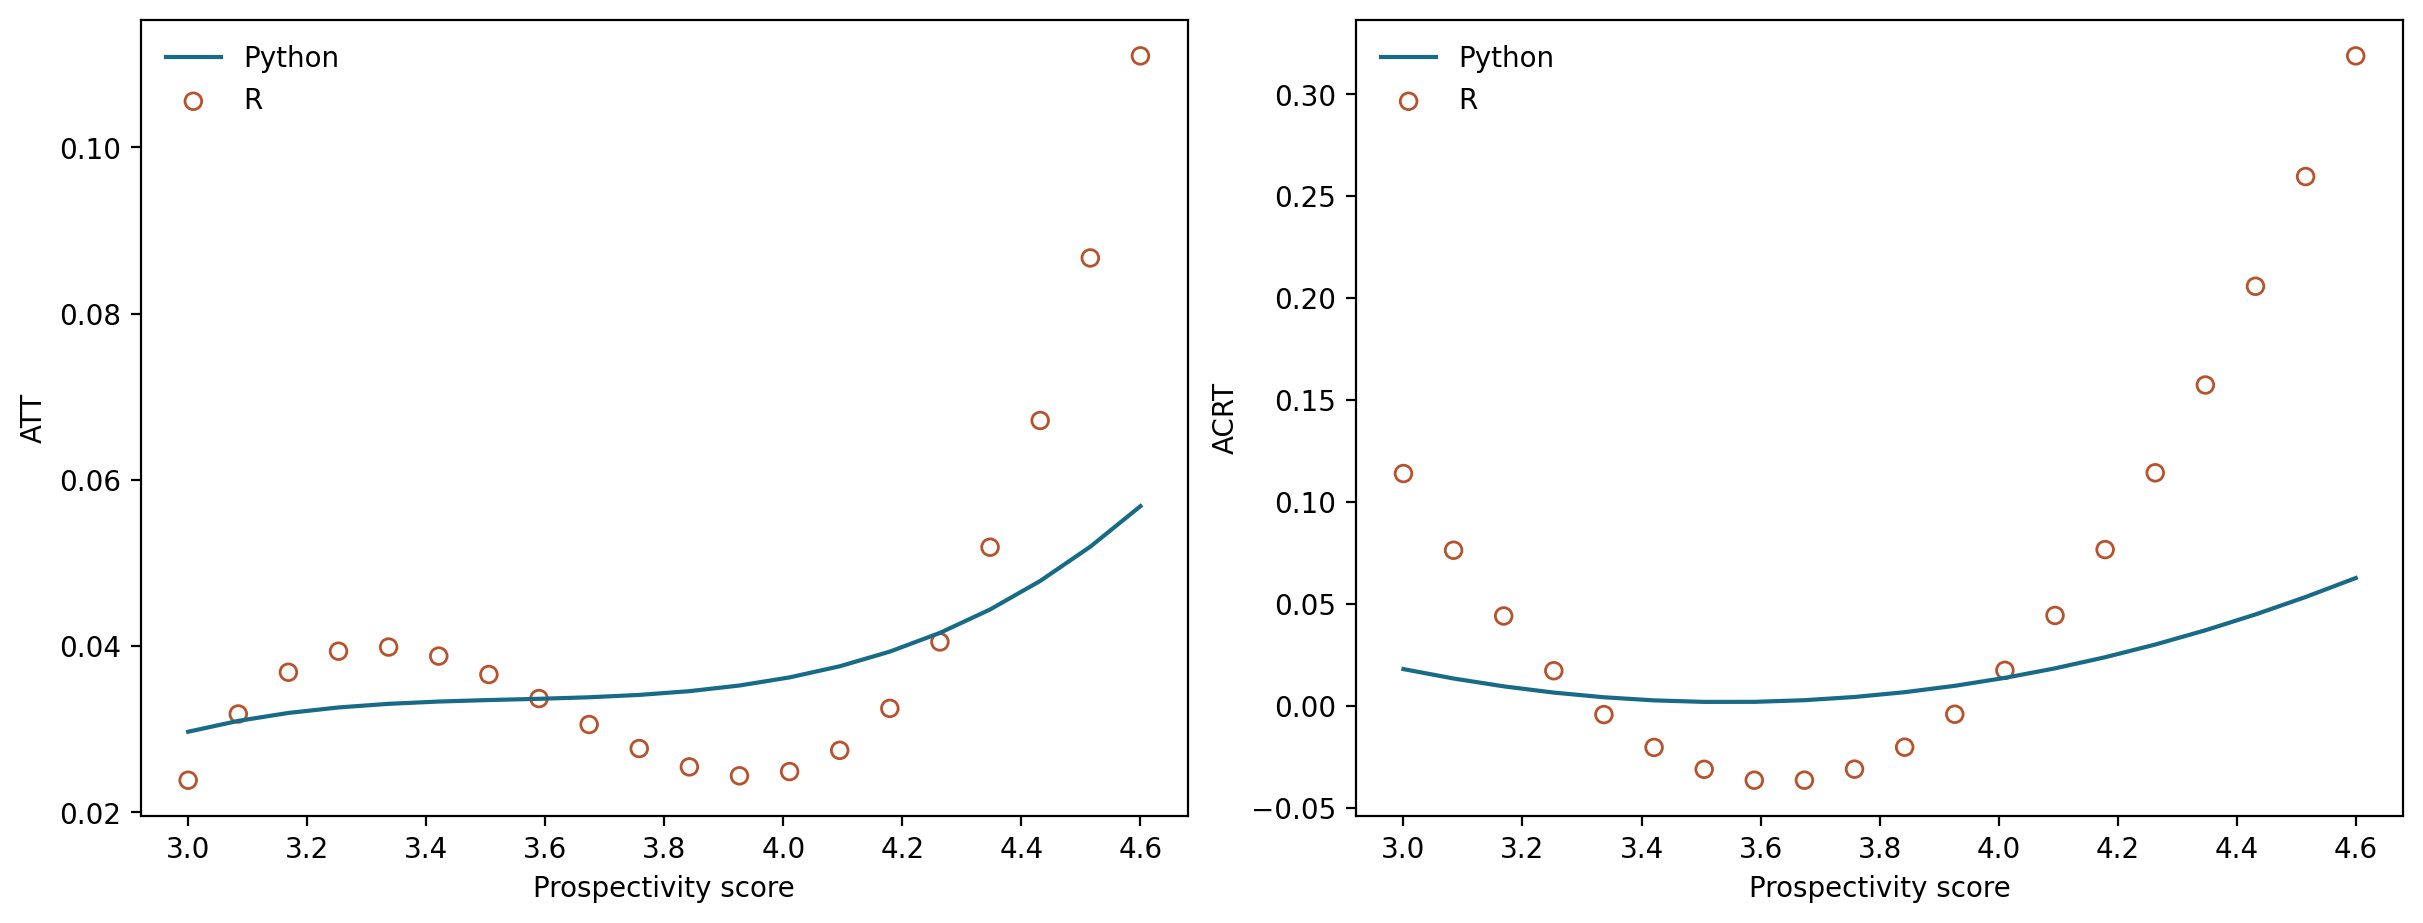

,dose,Python ATT,R ATT,ATT difference,Python SE,R SE,SE difference
0,3.00000000,0.02969805,0.02386443,0.00583362,0.01198102,0.01392712,-0.00194610
1,3.08421053,0.03100717,0.03183179,-0.00082462,0.01138273,0.01318751,-0.00180478
2,3.16842105,0.03195994,0.03685602,-0.00489609,0.01193978,0.01280037,-0.00086060
3,3.25263158,0.03262157,0.03939023,-0.00676867,0.01219441,0.01299917,-0.00080476
4,3.33684211,0.03305729,0.03988751,-0.00683023,0.01218961,0.01326643,-0.00107682
5,3.42105263,0.03333233,0.03880096,-0.00546863,0.01182384,0.01300852,-0.00118467
6,3.50526316,0.03351191,0.03658366,-0.00307175,0.01196499,0.01236902,-0.00040403
7,3.58947368,0.03366126,0.03368871,-0.00002745,0.01227063,0.01077492,0.00149571
8,3.67368421,0.03384560,0.03056920,0.00327640,0.01178406,0.01008233,0.00170173
9,3.75789474,0.03413016,0.02767823,0.00645193,0.01140083,0.00961293,0.00178790


,dose,Python ACRT,R ACRT,ACRT difference,Python SE,R SE,SE difference
0,3.00000000,0.01791990,0.11388061,-0.09596072,0.01230152,0.06465779,-0.05235627
1,3.08421053,0.01330086,0.07624083,-0.06293997,0.01176894,0.04928209,-0.03751316
2,3.16842105,0.00945637,0.04398153,-0.03452516,0.01167553,0.03867021,-0.02699467
3,3.25263158,0.00638644,0.01710273,-0.01071629,0.01156678,0.02914032,-0.01757353
4,3.33684211,0.00409105,-0.00439558,0.00848664,0.01141978,0.02405899,-0.01263921
5,3.42105263,0.00257022,-0.02051341,0.02308363,0.01194952,0.02076340,-0.00881389
6,3.50526316,0.00182394,-0.03125074,0.03307468,0.01218258,0.01750018,-0.00531760
7,3.58947368,0.00185221,-0.03660758,0.03845979,0.01127166,0.01996651,-0.00869485
8,3.67368421,0.00265504,-0.03658393,0.03923897,0.01006776,0.02280063,-0.01273287
9,3.75789474,0.00423241,-0.03117979,0.03541220,0.01017517,0.02358801,-0.01341284


In [7]:
with ro.default_converter.context():
    r_dose = np.asarray(r_fit.rx2("dose"))
    r_att = np.asarray(r_fit.rx2("att.d"))
    r_acrt = np.asarray(r_fit.rx2("acrt.d"))
    r_att_se = np.asarray(r_fit.rx2("att.d_se"))
    r_acrt_se = np.asarray(r_fit.rx2("acrt.d_se"))
np.testing.assert_array_equal(np.asarray(python_fit.dose), r_dose)

att_curve = pd.DataFrame({
    "dose": dvals,
    "Python ATT": python_fit.att_d,
    "R ATT": r_att,
    "ATT difference": np.asarray(python_fit.att_d) - r_att,
    "Python SE": python_fit.att_d_se,
    "R SE": r_att_se,
    "SE difference": np.asarray(python_fit.att_d_se) - r_att_se,
})
acrt_curve = pd.DataFrame({
    "dose": dvals,
    "Python ACRT": python_fit.acrt_d,
    "R ACRT": r_acrt,
    "ACRT difference": np.asarray(python_fit.acrt_d) - r_acrt,
    "Python SE": python_fit.acrt_d_se,
    "R SE": r_acrt_se,
    "SE difference": np.asarray(python_fit.acrt_d_se) - r_acrt_se,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), dpi=200, constrained_layout=True)
for ax, name, table in zip(axes, ["ATT", "ACRT"], [att_curve, acrt_curve], strict=True):
    ax.plot(table["dose"], table[f"Python {name}"], label="Python", color="#176b87")
    ax.scatter(table["dose"], table[f"R {name}"], label="R", facecolors="none", edgecolors="#b7532c")
    ax.set(xlabel="Prospectivity score", ylabel=name)
    ax.legend(frameon=False)
plt.show()

display(att_curve)
display(acrt_curve)

(r-comparisons-continuous-curves)=

### How R evaluates the curves

You can see in the figure that the curves part most at the top of the score
range. At a score of 4.6, ModernDiD puts the ATT at 0.057 and the ACRT at
0.063, against 0.111 and 0.319 in R. Across the grid, ModernDiD's ACRT curve
stays between 0.002 and 0.063. R's ACRT falls from 0.114 to −0.037 before it
climbs to 0.319.

Both packages fit each cohort's spline on a basis whose boundary knots are the
smallest and largest scores observed in that cohort. ModernDiD then evaluates
that fit at the grid scores on the same basis. In `contdid`, `cont_did_acrt`
instead applies the coefficients to `bs_grid`, a basis built on `dvals` alone
that takes its boundary knots from the grid's endpoints, 3.0 and 4.6. With
degree 3 and no interior knots, the basis consists of cubic Bernstein
polynomials on the interval between its boundary knots.

:::{admonition} R's dose curves aren't the fitted curves
:class: warning

Since the same coefficients describe a different cubic on a different
interval, R's ATT(d) and ACRT(d) are not the cohort's fitted dose response and
its derivative, the curves that Callaway, Goodman-Bacon, and Sant'Anna (2025)
estimate. Report ModernDiD's curves instead, since they evaluate each fit on
the basis it was estimated on and keep their values when you change the
grid.
:::

The cell below prints the two lines of the installed `cont_did_acrt` that
build the fitting basis `bs` and the evaluation basis `bs_grid`. Its table
sets each cohort's observed range beside the grid boundaries that R uses.
The [splines2 documentation](https://wwenjie.org/splines2/reference/bspline)
explains how the boundary knots default to the input's range. The [contdid
source](https://github.com/bcallaway11/contdid/blob/master/R/cont_did.R) on
GitHub holds the level and derivative calculations. In `ptetools`,
`process_dose_gt` builds the influence functions of the curves on the same
grid basis (`R/process_dose_gt.R`, lines 85 to 88).

In [8]:
cohorts = data.filter(pl.col("G") > 0).select("i", "G", "d").unique().sort(["G", "i"])
with ro.default_converter.context():
    r_source = list(ro.r("deparse(body(contdid::cont_did_acrt))"))
    for index, line in enumerate(r_source):
        if "bs <- as.data.frame" in line or "bs_grid <- as.data.frame" in line:
            print(line.strip())
            print(r_source[index + 1].strip())

    boundaries = []
    for cohort in cohorts["G"].unique().sort():
        observed = cohorts.filter(pl.col("G") == cohort)["d"].to_numpy()
        ro.globalenv["observed_doses"] = ro.FloatVector(observed)
        observed_bounds = np.asarray(ro.r('attr(splines2::bSpline(observed_doses, degree = 3), "Boundary.knots")'))
        grid_bounds = np.asarray(ro.r('attr(splines2::bSpline(dvals, degree = 3), "Boundary.knots")'))
        boundaries.append([cohort + first_year - 1, *observed_bounds, *grid_bounds])
display(pd.DataFrame(boundaries, columns=[
    "adoption year", "observed minimum", "observed maximum", "R grid minimum", "R grid maximum"
]))

bs <- as.data.frame(splines2::bSpline(dose[dose > 0], degree = degree,
knots = knots))
bs_grid <- as.data.frame(splines2::bSpline(dvals, degree = degree,
knots = knots))


,adoption year,observed minimum,observed maximum,R grid minimum,R grid maximum
0,2001,1.34000003,5.00000000,3.0,4.6
1,2005,2.17000008,4.82999992,3.0,4.6
2,2006,2.66000009,5.00000000,3.0,4.6
3,2007,2.99000001,9.34000015,3.0,4.6
4,2008,0.20000000,5.00000000,3.0,4.6
5,2009,2.67000008,4.67000008,3.0,4.6
6,2010,2.40000010,5.00000000,3.0,4.6
7,2012,1.79999995,4.67000008,3.0,4.6


### Repeat the comparison on a narrower grid

We repeat both calls with the outer three scores removed from each end of
`dvals`. All observations, estimator settings, and interior knots stay the
same. The table reports the largest change in each curve at the 14 scores
that both grids share. A curve that is the fitted dose response does not
change at those scores, whatever grid you pass. The overall summaries use
the observed scores and do not depend on the grid.

In [9]:
narrow_dvals = dvals[3:-3]
narrow_python = did.cont_did(
    data,
    yname="y", tname="t", idname="i", gname="G", dname="d",
    target_parameter="level", aggregation="dose", treatment_type="continuous",
    dose_est_method="parametric", control_group="notyettreated", base_period="varying",
    degree=3, num_knots=0, dvals=narrow_dvals,
    biters=199, cband=False, random_state=42,
)
with ro.default_converter.context():
    ro.globalenv["narrow_dvals"] = ro.FloatVector(narrow_dvals)
    ro.r("set.seed(42)")
    narrow_r = ro.r("""
        contdid::cont_did(
            data = panel,
            yname = "y", tname = "t", idname = "i", gname = "G", dname = "d",
            target_parameter = "level", aggregation = "dose", treatment_type = "continuous",
            dose_est_method = "parametric", control_group = "notyettreated", base_period = "varying",
            degree = 3, num_knots = 0, dvals = narrow_dvals,
            bstrap = TRUE, biters = 199, cband = FALSE
        )
    """)
    np.testing.assert_array_equal(np.asarray(narrow_r.rx2("dose")), narrow_dvals)
    narrow_r_att = np.asarray(narrow_r.rx2("att.d"))
    narrow_r_acrt = np.asarray(narrow_r.rx2("acrt.d"))
np.testing.assert_array_equal(np.asarray(narrow_python.dose), narrow_dvals)

grid_changes = pd.DataFrame([
    {
        "curve": name,
        "Python maximum change at shared scores": np.max(np.abs(py_narrow - py_full[3:-3])),
        "R maximum change at shared scores": np.max(np.abs(r_narrow - r_full[3:-3])),
    }
    for name, py_full, py_narrow, r_full, r_narrow in (
        ("ATT", np.asarray(python_fit.att_d), np.asarray(narrow_python.att_d), r_att, narrow_r_att),
        ("ACRT", np.asarray(python_fit.acrt_d), np.asarray(narrow_python.acrt_d), r_acrt, narrow_r_acrt),
    )
])
np.testing.assert_allclose(grid_changes["Python maximum change at shared scores"], 0, atol=1e-12)
display(grid_changes)

/Users/jordandeklerk/moderndid/moderndid/didcont/estimation/process_attgt.py:91: UserWarning: Not returning pre-test Wald statistic due to singular covariance matrix
  warnings.warn("Not returning pre-test Wald statistic due to singular covariance matrix", UserWarning)
R callback write-console: In addition:   
R callback write-console: Warning message:
  
R callback write-console: In mboot2(thisinffunc, biters = biters, alp = alp) :  
R callback write-console: 
   
R callback write-console:  critical value for uniform confidence band is somehow smaller than
            critical value for pointwise confidence interval...using pointwise
            confidence interal
  


,curve,Python maximum change at shared scores,R maximum change at shared scores
0,ATT,0.0,0.05911841
1,ACRT,0.0,0.30861885


Both of ModernDiD's curves keep the same value at every score that the two
grids share. Although only the grid changed, R's ATT moves by up to 0.059 at
those scores and its ACRT by up to 0.309.

(r-comparisons-continuous-inference)=

## Compare inference before bootstrap draws

An influence function (IF) describes each county's contribution to sampling
uncertainty before any multiplier draws. The next table applies
`sqrt(sum(IF**2)) / n` to the influence functions that both fits return. For
each curve it reports the largest of the 20 values on each side and the
largest gap between them. Of the four rows, the overall ACRT shows the
largest relative gap.

In [10]:
with ro.default_converter.context():
    r_overall_att_if = np.asarray(r_fit.rx2("overall_att_inffunc")).reshape(-1)
    r_overall_acrt_if = np.asarray(r_fit.rx2("overall_acrt_inffunc")).reshape(-1)
    r_att_curve_if = np.asarray(r_fit.rx2("att.d_inffunc"))
    r_acrt_curve_if = np.asarray(r_fit.rx2("acrt.d_inffunc"))


def influence_se(values):
    """Return the standard error that each column of an influence function implies."""
    values = np.asarray(values)
    assert np.isfinite(values).all()
    assert values.shape[0] == data["i"].n_unique()
    return np.sqrt(np.sum(values**2, axis=0)) / values.shape[0]


inference_rows = []
for name, python_if, r_if in (
    ("Overall ATT", python_fit.overall_att_inf_func, r_overall_att_if),
    ("Overall ACRT", python_fit.overall_acrt_inf_func, r_overall_acrt_if),
    ("ATT curve", python_fit.att_d_inf_func, r_att_curve_if),
    ("ACRT curve", python_fit.acrt_d_inf_func, r_acrt_curve_if),
):
    python_se, r_se = influence_se(python_if), influence_se(r_if)
    inference_rows.append({
        "quantity": name,
        "largest Python SE implied by IF": np.max(python_se),
        "largest R SE implied by IF": np.max(r_se),
        "largest absolute SE difference": np.max(np.abs(python_se - r_se)),
    })
display(pd.DataFrame(inference_rows))

,quantity,largest Python SE implied by IF,largest R SE implied by IF,largest absolute SE difference
0,Overall ATT,0.00941825,0.00925074,0.00016751
1,Overall ACRT,0.00989659,0.00286722,0.00702937
2,ATT curve,0.01199243,0.01577051,0.00377808
3,ACRT curve,0.02587350,0.07618477,0.06228298


ModernDiD's influence function gives the overall ACRT a standard error of
0.0099, against 0.0029 in R. In `contdid`, `cont_did_acrt` returns each
cell's ACRT influence function on the cell's treated counties alone.
`ptetools` then multiplies every cell's influence function by n/n1 with n1
the number of counties in the whole cell (`R/pte.R`, line 137). Since the
ACRT averages over treated counties, ModernDiD scales by n over the number
of treated counties instead. R's factor shrinks each cell's term by the
treated share of the cell. In the first post-adoption year of the 2001
cohort, that share is 34 of 402 counties.

`process_dose_gt` also averages the cell influence functions with the cohort
weights held fixed (`R/process_dose_gt.R`, line 74). Since those weights are
estimated cohort shares, ModernDiD adds the term that their estimation
contributes. The scaling accounts for most of the gap and the weight term
for the rest.

:::{admonition} R's ACRT interval is too narrow
:class: warning

R prints an overall ACRT interval from 0.0372 to 0.0511 around the same
estimate, about a third as wide as ModernDiD's interval from 0.0236 to 0.0648.
The scaling above, rather than any extra precision, makes R's interval
narrower. Report ModernDiD's interval, since its influence function scales
each cell by the treated counties that the ACRT averages over and adds the
term for estimated cohort weights.
:::

The overall ATT values differ only slightly, 0.00942 in ModernDiD against
0.00925 in R. Before it builds the term for estimated cohort shares,
`pte_aggte` rescales the shares to sum to one (`R/pte_aggte.R`, lines 66 and
67). That term then comes out multiplied by the share of counties ever
treated, 329 of 402 here.

For the curves, `process_dose_gt` builds the influence functions on the grid
basis and combines the cells with fixed weights (lines 123 and 148). Line 118
also negates the comparison counties' term in ATT(d). Since the stored binary
ATT influence function already gives that term its sign, the negation flips
it. On this data the flip changes the curve standard errors by at most 0.1
percent. The largest curve values, 0.0120 against 0.0158 for ATT(d) and 0.0259
against 0.0762 for ACRT(d), sit at the ends of the grid.

The last cell asserts that the two overall estimates agree within
`1e-6 + 1e-5 * abs(R estimate)` and lists the largest gap in each
comparison.

In [11]:
np.testing.assert_allclose(overall["Python estimate"], overall["R estimate"], rtol=1e-5, atol=1e-6)
differences = pd.DataFrame([
    {
        "comparison": "overall estimates",
        "largest absolute estimate difference": overall["estimate difference"].abs().max(),
        "largest absolute SE difference": overall["SE difference"].abs().max(),
    },
    {
        "comparison": "ATT curve",
        "largest absolute estimate difference": att_curve["ATT difference"].abs().max(),
        "largest absolute SE difference": att_curve["SE difference"].abs().max(),
    },
    {
        "comparison": "ACRT curve",
        "largest absolute estimate difference": acrt_curve["ACRT difference"].abs().max(),
        "largest absolute SE difference": acrt_curve["SE difference"].abs().max(),
    },
])
display(differences)

,comparison,largest absolute estimate difference,largest absolute SE difference
0,overall estimates,6.24500451e-17,0.00696569
1,ATT curve,5.41814261e-02,0.00428723
2,ACRT curve,2.56182074e-01,0.05426675


The curve rows repeat the grid-basis gaps from the figure. Their
standard-error gaps combine independent draws with the influence-function
differences traced above.

## Overall effects in an event study

Although this page fits dose curves, the two packages also report different
overall effects in an event study. With `aggregation="eventstudy"`,
{func}`~moderndid.cont_did` follows Callaway and Sant'Anna (2021) and reports
the average of the event-study effects from the start of treatment on as
`overall_att`. `contdid` computes that average too but returns its group
aggregation as the top-level `overall_att`. Since both are defensible
summaries, the two numbers differ by definition.

## Versions used

These versions of Python, R, and the packages produced the output shown on
this page.

In [12]:
from importlib.metadata import version
from platform import python_version

with ro.default_converter.context():
    r_version = str(ro.r("R.version.string")[0])
    contdid_version = str(ro.r('as.character(packageVersion("contdid"))')[0])
    ptetools_version = str(ro.r('as.character(packageVersion("ptetools"))')[0])
display(pd.DataFrame({
    "component": ["Python", "ModernDiD", "rpy2", "R", "contdid", "ptetools"],
    "version": [python_version(), version("moderndid"), version("rpy2"), r_version, contdid_version, ptetools_version],
}))

,component,version
0,Python,3.12.10
1,ModernDiD,0.2.0
2,rpy2,3.6.4
3,R,R version 4.3.3 (2024-02-29)
4,contdid,0.1.1
5,ptetools,1.0.1
